In [1]:
from sklearn.datasets import fetch_20newsgroups
import pandas as pd

data = fetch_20newsgroups(
    subset="all",
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=42
)

dataset = pd.DataFrame({
    "Text": data.data,
    "Category": [data.target_names[i] for i in data.target]
})

dataset.to_csv("20_newsgroups_dataset.csv", index=False)

print("Dataset downloaded successfully!")
print("Total records:", len(dataset))
display(dataset.head())


Dataset downloaded successfully!
Total records: 18846


,Text,Category
0,\n\nI am sure some bashers of Pens fans are pr...,rec.sport.hockey
1,My brother is in the market for a high-perform...,comp.sys.ibm.pc.hardware
2,\n\n\n\n\tFinally you said what you dream abou...,talk.politics.mideast
3,\nThink!\n\nIt's the SCSI card doing the DMA t...,comp.sys.ibm.pc.hardware
4,1) I have an old Jasmine drive which I cann...,comp.sys.mac.hardware


In [2]:
from google.colab import files
files.download("20_newsgroups_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# Display dataset information

print("Dataset Shape:", dataset.shape)

print("\nFirst 10 Text Records:")
display(dataset.head(10))

print("\nCategory Distribution:")
print(dataset["Category"].value_counts())

print("\nMissing Values:")
print(dataset.isnull().sum())

print("\nTotal Categories:", dataset["Category"].nunique())

Dataset Shape: (18846, 2)

First 10 Text Records:


,Text,Category
0,\n\nI am sure some bashers of Pens fans are pr...,rec.sport.hockey
1,My brother is in the market for a high-perform...,comp.sys.ibm.pc.hardware
2,\n\n\n\n\tFinally you said what you dream abou...,talk.politics.mideast
3,\nThink!\n\nIt's the SCSI card doing the DMA t...,comp.sys.ibm.pc.hardware
4,1) I have an old Jasmine drive which I cann...,comp.sys.mac.hardware
5,\n\nBack in high school I worked as a lab assi...,sci.electronics
6,\n\nAE is in Dallas...try 214/241-6060 or 214/...,comp.sys.mac.hardware
7,"\n[stuff deleted]\n\nOk, here's the solution t...",rec.sport.hockey
8,"\n\n\nYeah, it's the second one. And I believ...",rec.sport.hockey
9,\nIf a Christian means someone who believes in...,talk.religion.misc



Category Distribution:
Category
rec.sport.hockey            999
soc.religion.christian      997
rec.motorcycles             996
rec.sport.baseball          994
sci.crypt                   991
rec.autos                   990
sci.med                     990
comp.windows.x              988
sci.space                   987
comp.os.ms-windows.misc     985
sci.electronics             984
comp.sys.ibm.pc.hardware    982
misc.forsale                975
comp.graphics               973
comp.sys.mac.hardware       963
talk.politics.mideast       940
talk.politics.guns          910
alt.atheism                 799
talk.politics.misc          775
talk.religion.misc          628
Name: count, dtype: int64

Missing Values:
Text        0
Category    0
dtype: int64

Total Categories: 20


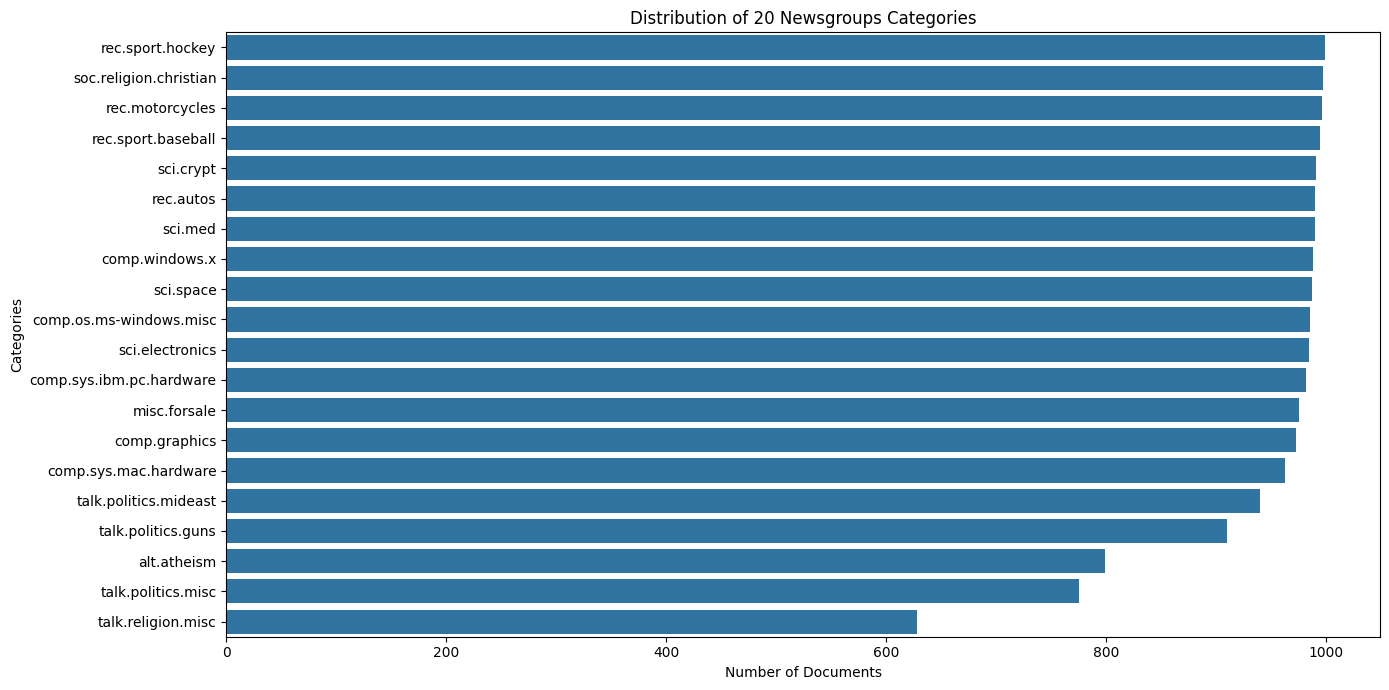

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.countplot(
    data=dataset,
    y="Category",
    order=dataset["Category"].value_counts().index
)

plt.title("Distribution of 20 Newsgroups Categories")
plt.xlabel("Number of Documents")
plt.ylabel("Categories")
plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X = dataset["Text"]
y = dataset["Category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 15076
Testing Records: 3770


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into numerical TF-IDF features
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Fit on training data and transform both datasets
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Feature Extraction Completed!")
print("Training Feature Shape:", X_train_tfidf.shape)
print("Testing Feature Shape:", X_test_tfidf.shape)
print("Total Features:", len(tfidf.get_feature_names_out()))

TF-IDF Feature Extraction Completed!
Training Feature Shape: (15076, 20000)
Testing Feature Shape: (3770, 20000)
Total Features: 20000


In [7]:
feature_names = tfidf.get_feature_names_out()

print("First 20 TF-IDF Features:")
print(feature_names[:20])

print("\nSample TF-IDF Values:")
print(X_train_tfidf[0, :20].toarray())

First 20 TF-IDF Features:
['00' '00 00' '00 000' '00 01' '00 02' '00 10' '00 50' '00 april'
 '00 book' '00 force' '00 incredible' '00 new' '00 pm' '00 shipping'
 '00 web' '00 wolverine' '000' '000 00' '000 000' '000 feet']

Sample TF-IDF Values:
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

import time
import pandas as pd

# Create four machine learning models
models = {
    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=50,
        min_samples_leaf=2,
        random_state=42
    ),

    "SVM": LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ),

    "Naive Bayes": MultinomialNB()
}

trained_models = {}
training_times = {}

# Train all four models
for name, model in models.items():

    print("\nTraining:", name)

    start_time = time.time()

    model.fit(X_train_tfidf, y_train)

    end_time = time.time()

    trained_models[name] = model
    training_times[name] = end_time - start_time

    print(name, "training completed!")
    print("Training Time:", round(training_times[name], 2), "seconds")

print("\nAll four models trained successfully!")


Training: KNN
KNN training completed!
Training Time: 0.03 seconds

Training: Decision Tree
Decision Tree training completed!
Training Time: 11.65 seconds

Training: SVM
SVM training completed!
Training Time: 1.22 seconds

Training: Naive Bayes
Naive Bayes training completed!
Training Time: 0.06 seconds

All four models trained successfully!


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_tfidf)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,KNN,0.6637,0.6962,0.6569,0.6663
1,Decision Tree,0.3775,0.6068,0.3665,0.4238
2,SVM,0.7531,0.7569,0.7441,0.7465
3,Naive Bayes,0.7223,0.7494,0.7030,0.6957


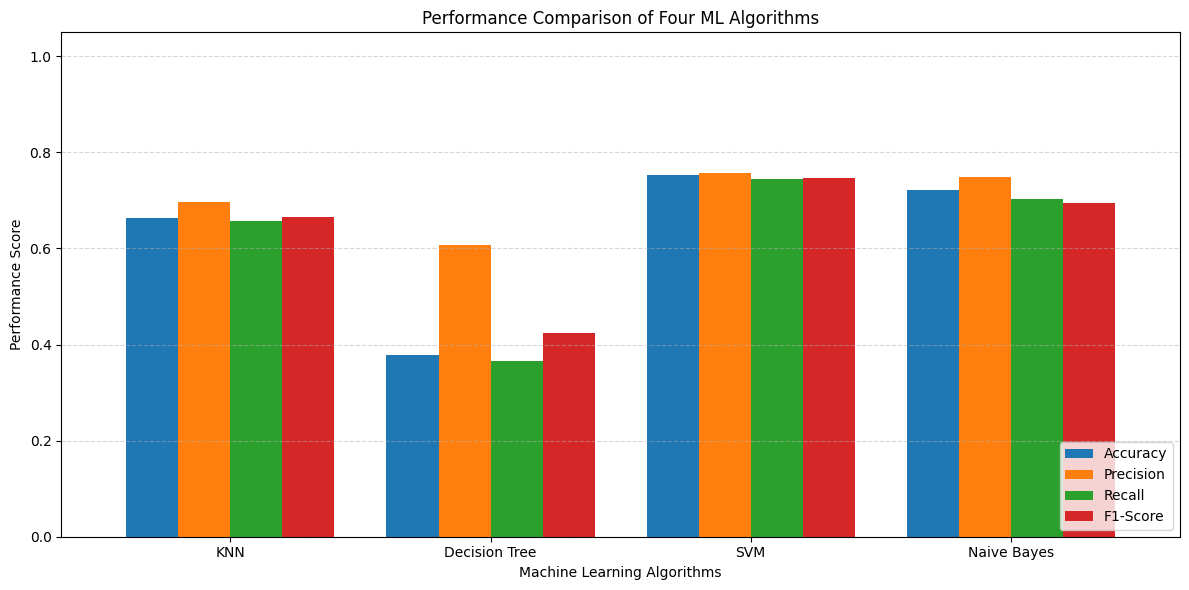

In [10]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_plot = results_df.set_index("Algorithm")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of Four ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig("algorithm_comparison.png", dpi=300)
plt.show()

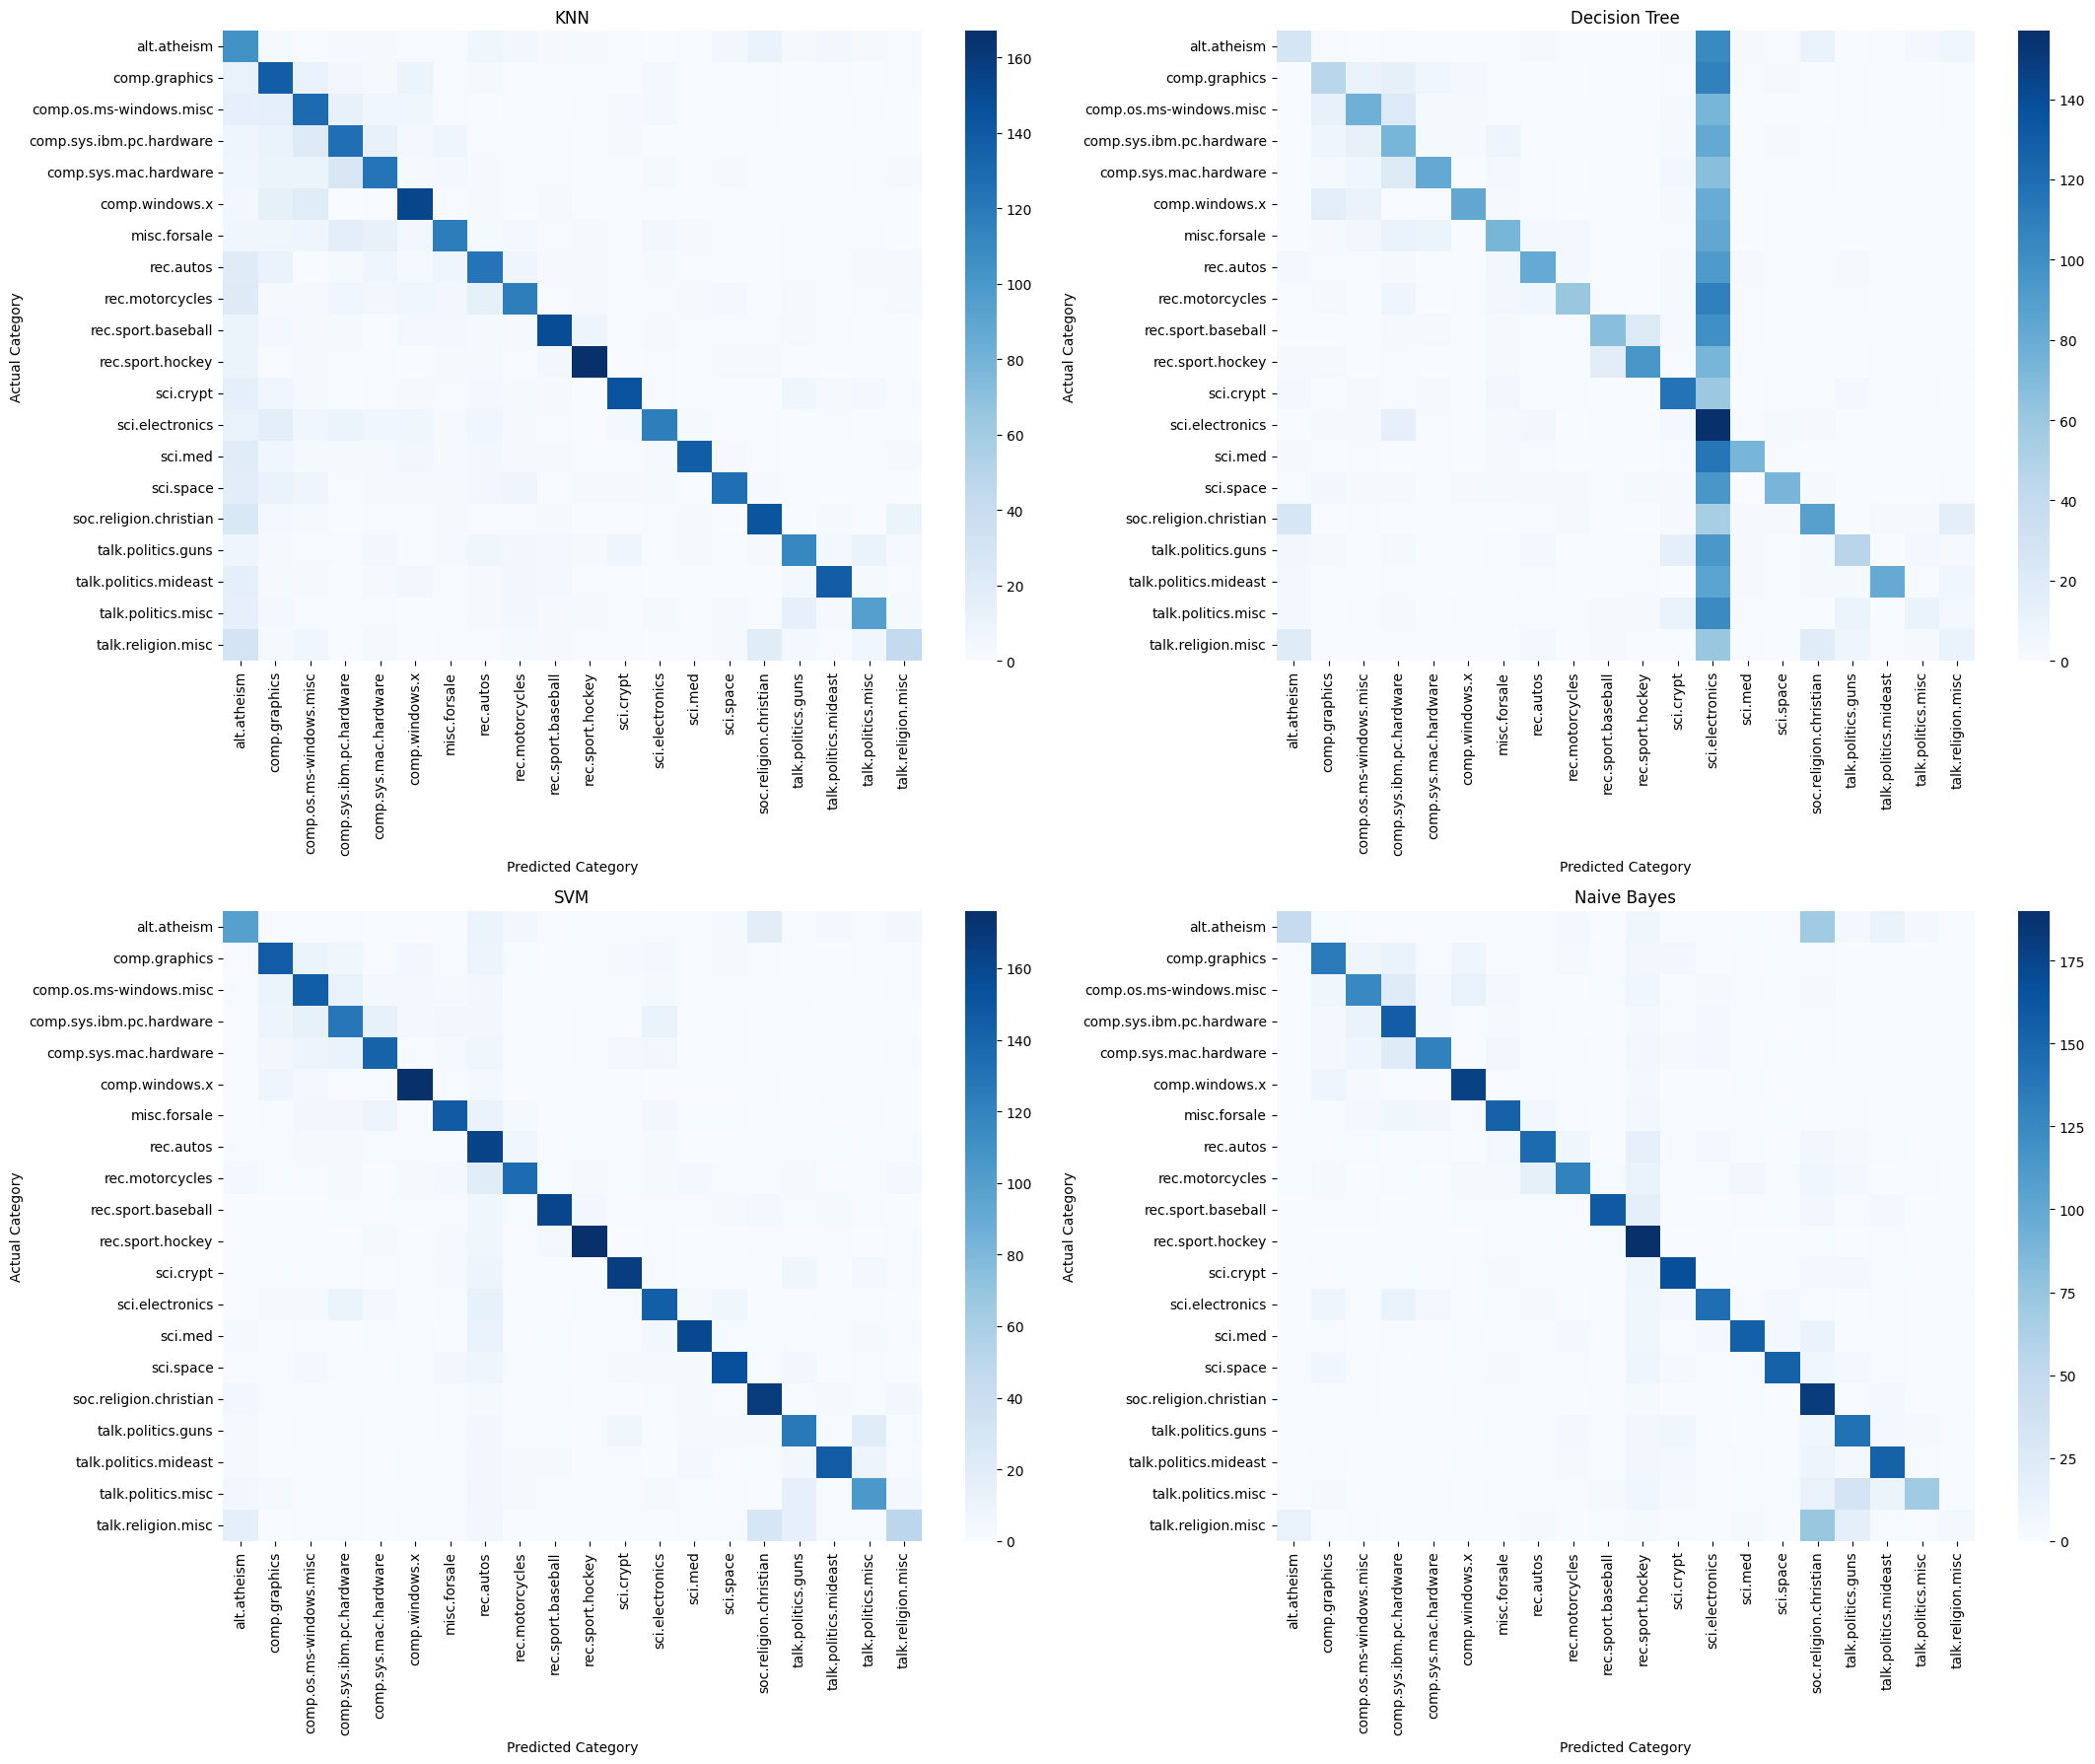

In [11]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(22, 18))
axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):

    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=sorted(dataset["Category"].unique())
    )

    sns.heatmap(
        cm,
        ax=axes[i],
        cmap="Blues",
        annot=False,
        xticklabels=sorted(dataset["Category"].unique()),
        yticklabels=sorted(dataset["Category"].unique())
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Category")
    axes[i].set_ylabel("Actual Category")
    axes[i].tick_params(axis="x", labelrotation=90)
    axes[i].tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.savefig("four_confusion_matrices.png", dpi=300)
plt.show()

In [12]:
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("BEST PERFORMING ALGORITHM")
print("-------------------------")
print("Algorithm:", best_model["Algorithm"])
print("Accuracy:", round(best_model["Accuracy"] * 100, 2), "%")
print("Precision:", round(best_model["Precision"] * 100, 2), "%")
print("Recall:", round(best_model["Recall"] * 100, 2), "%")
print("F1-Score:", round(best_model["F1-Score"] * 100, 2), "%")

BEST PERFORMING ALGORITHM
-------------------------
Algorithm: SVM
Accuracy: 75.31 %
Precision: 75.69 %
Recall: 74.41 %
F1-Score: 74.65 %


In [13]:
from google.colab import files

files.download("20_newsgroups_dataset.csv")
files.download("algorithm_comparison.png")
files.download("four_confusion_matrices.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>